# **Pós-Graduação em Dára Science and Digital Transformation**

## *Ambientes de Programação para Ciência de Dados*
### Projeto 2
---
Ana Estreia

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")

## PARTE 1



In [ ]:
df = pd.read_excel("dataset_PIAES_reduced.xlsx")
df.shape

(5742, 13)

O conjunto de dados apresenta uma dimensão de 5742 linhas e 13 colunas.
Isto traduz-se em **5742 estudantes** e **13 atributos**.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5742 entries, 0 to 5741
Data columns (total 13 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Sexo (M/F)                        5742 non-null   object 
 1   Estado civil (desc)               5742 non-null   object 
 2   Ordem de ingresso                 5742 non-null   int64  
 3   Curso (desc)                      5742 non-null   object 
 4   Deslocado (S/N)                   5742 non-null   object 
 5   Nacionalidade (desc)              5742 non-null   object 
 6   Habilitação literária mãe (desc)  5722 non-null   object 
 7   Situação profissional mãe (desc)  5742 non-null   object 
 8   Situação profissional pai (desc)  5742 non-null   object 
 9   Nota ingresso                     5674 non-null   float64
 10  Bolseiro                          5742 non-null   int64  
 11  Idade no ingresso                 5691 non-null   float64
 12  Catego

In [ ]:
# Listar colunas numéricas e categóricas
cols_numericas = df.select_dtypes(include=['int64', 'float64']).columns
cols_categoricas = df.select_dtypes(include=['object']).columns

print("Numéricas:", cols_numericas.values)
print("Categóricas:", cols_categoricas.values)

Numéricas: ['Ordem de ingresso' 'Nota ingresso' 'Bolseiro' 'Idade no ingresso']
Categóricas: ['Sexo (M/F)' 'Estado civil (desc)' 'Curso (desc)' 'Deslocado (S/N)'
 'Nacionalidade (desc)' 'Habilitação literária mãe (desc)'
 'Situação profissional mãe (desc)' 'Situação profissional pai (desc)'
 'Categoria']


**Variáveis Numéricas:** 4 atributos (Ordem de ingresso, Nota ingresso, Bolseiro, Idade no ingresso). A variável 'Bolseiro', apesar de ser numérica (int64), é concetualmente uma variável categórica binária (0 ou 1).

**Variáveis Categóricas (Object):** 9 atributos, que descrevem o perfil sociodemográfico e académico (ex: Curso, Nacionalidade, Sexo), incluindo a variável alvo Categoria.

**Qualidade dos Dados:** Foi detetada a presença de valores em falta (Null/NaN) em três colunas, que exigirão tratamento na fase de pré-processamento:

**Nota ingresso:** 68 valores em falta.

**Idade no ingresso:** 51 valores em falta.

**Habilitação literária mãe:** 20 valores em falta.

In [ ]:
df['Categoria'].value_counts()

,count
Categoria,
Não Diplomado,3264
Diplomado,2478


In [ ]:
# Ver a percentagem de cada classe
df['Categoria'].value_counts(normalize=True) * 100

,proportion
Categoria,
Não Diplomado,56.844305
Diplomado,43.155695


**Não Diplomado:** 3264 estudantes<br>
**Diplomado:** 2478 estudantes

Observa-se que as classes não estão perfeitamente balanceadas, existindo uma prevalência da classe **Não Diplomado** (representando cerca de 57% dos dados). Embora não seja um desequilíbrio extremo, é importante ter este fator em conta na avaliação futura dos modelos.

## PARTE 2 - Análise exploratória

Para esta parte serão analisadas as colunas **Nota de Ingresso**, **Idade no Ingresso** e **Deslocado**.

In [ ]:
df['Nota ingresso'].describe()

,Nota ingresso
count,5674.000000
mean,126.764406
std,14.679133
min,45.200000
25%,117.400000
50%,125.700000
75%,134.800000
max,190.000000


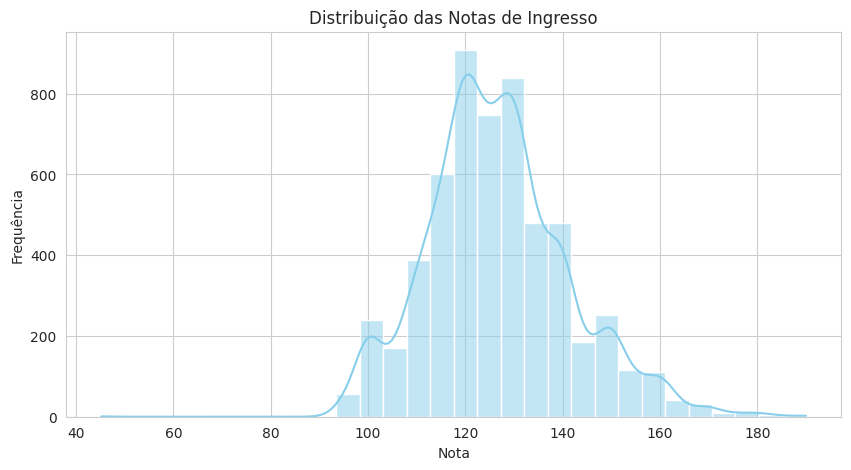

In [ ]:
# Nota de Ingresso
plt.figure(figsize=(10, 5))
sns.histplot(df['Nota ingresso'], bins=30, kde=True, color='skyblue')
plt.title('Distribuição das Notas de Ingresso')
plt.xlabel('Nota')
plt.ylabel('Frequência')
plt.show()

A análise estatística e o histograma revelam uma distribuição com **tendência central forte** (média ~126.8). A curva aproxima-se de uma distribuição normal, com a maioria dos alunos concentrada entre os 115 e 140 valores.

In [ ]:
df['Idade no ingresso'].describe()

,Idade no ingresso
count,5691.000000
mean,23.194166
std,7.313257
min,17.000000
25%,19.000000
50%,20.000000
75%,25.000000
max,61.000000


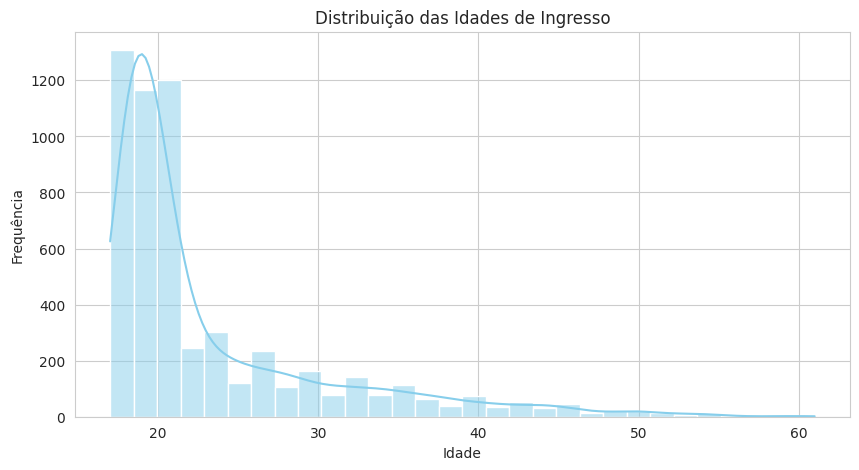

In [ ]:
# Idade de Ingresso
plt.figure(figsize=(10, 5))
sns.histplot(df['Idade no ingresso'], bins=30, kde=True, color='skyblue')
plt.title('Distribuição das Idades de Ingresso')
plt.xlabel('Idade')
plt.ylabel('Frequência')
plt.show()

Ao contrário da nota, a idade apresenta uma **distribuição assimétrica à direita**.

**Observação:** O pico da distribuição ocorre nas idades típicas de entrada no Ensino Superior (18-20 anos). A "cauda" longa à direita indica a presença de um grupo menor de estudantes mais velhos (maiores de 23 anos), possivelmente trabalhadores-estudantes, cujo perfil de risco escolar poderá ser diferente.

In [ ]:
# Deslocado
df['Deslocado (S/N)'].value_counts()


,count
Deslocado (S/N),
S,2993
N,2749


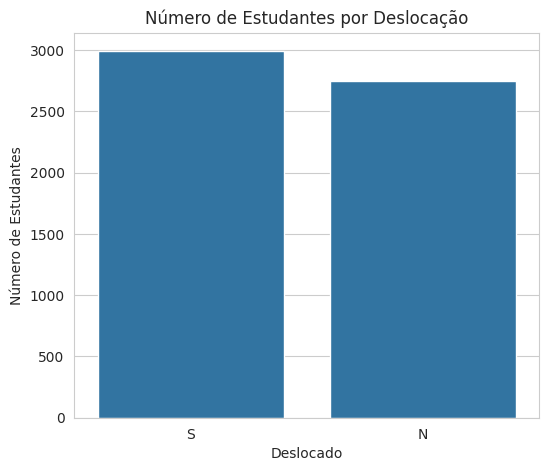

In [ ]:
# Deslocado
plt.figure(figsize=(6, 5))
sns.countplot(data=df, x='Deslocado (S/N)')
plt.title('Número de Estudantes por Deslocação')
plt.xlabel('Deslocado')
plt.ylabel('Número de Estudantes')
plt.show()

A deslocação do estudante da sua residência habitual para frequentar o ensino superior é um indicador indireto do esforço financeiro e pessoal investido na formação.

**Observação** O gráfico permite visualizar a proporção de estudantes que são deslocados versus os que residem na zona. Verifica-se que o corpo estudantil é composto por ambos os grupos, permitindo uma comparação robusta.

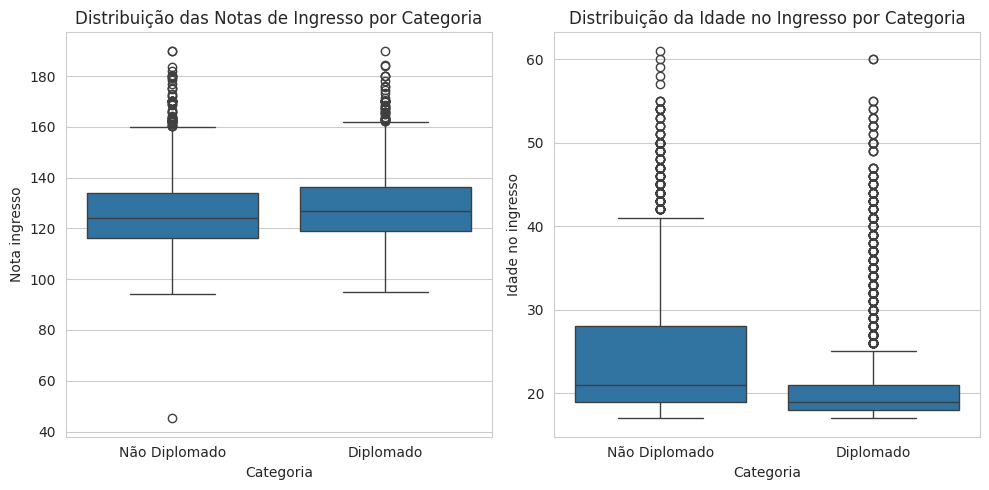

In [ ]:
# --- Relação com a Categoria ---

# Variáveis Numéricas vs Categoria (Boxplots)
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# Nota de Ingresso x Sucesso
sns.boxplot(data=df, x='Categoria', y='Nota ingresso', ax=axes[0])
axes[0].set_title('Distribuição das Notas de Ingresso por Categoria')

# Nota de Ingresso x Sucesso
sns.boxplot(data=df, x='Categoria', y='Idade no ingresso', ax=axes[1])
axes[1].set_title('Distribuição da Idade no Ingresso por Categoria')

plt.tight_layout()
plt.show()



**Nota de Ingresso**

A sobreposição das caixas sugere que a nota de entrada **não é**, isoladamente, **um fator determinante** para a conclusão do curso. O sucesso parece depender mais do percurso dentro da instituição do que da nota com que entraram.

**Idade no Ingresso**
O grupo dos Diplomados apresenta uma distribuição de idades mais concentrada e com uma mediana mais baixa (geralmente entre os 18-21 anos).No grupo dos "Não Diplomados", observa-se uma maior dispersão dos dados. Isto indica que os estudantes que ingressam com idades mais avançadas têm uma probabilidade estatística maior de não concluir o curso.

A **idade** no ingresso afirma-se como um preditor forte. O atraso no ingresso (reingressos ou estudantes mais velhos) está correlacionado com maiores taxas de insucesso, possivelmente devido a conflitos com outras responsabilidades (trabalho/família) que os alunos mais jovens não têm.

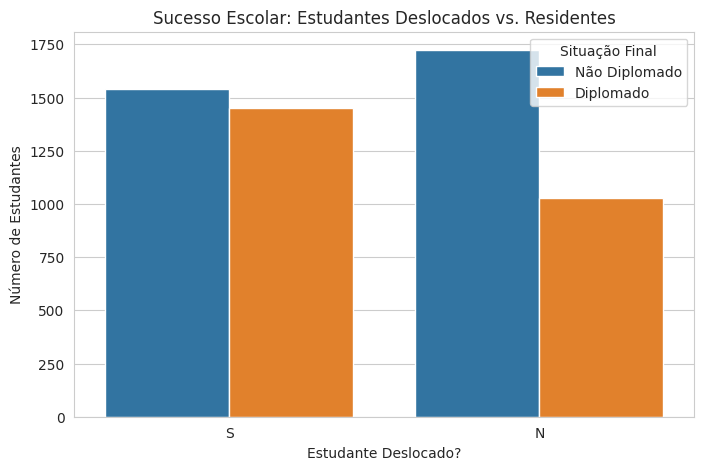

Taxa de Sucesso por Estatuto de Deslocado (%):
Categoria        Diplomado  Não Diplomado
Deslocado (S/N)                          
N                37.322663      62.677337
S                48.513197      51.486803


In [ ]:
# Deslocado x Sucesso
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='Deslocado (S/N)', hue='Categoria')

plt.title('Sucesso Escolar: Estudantes Deslocados vs. Residentes')
plt.xlabel('Estudante Deslocado?')
plt.ylabel('Número de Estudantes')
plt.legend(title='Situação Final')
plt.show()

# tabela de Proporções (Para ver a % exata de sucesso)
tabela_deslocado = pd.crosstab(df['Deslocado (S/N)'], df['Categoria'], normalize='index') * 100
print("Taxa de Sucesso por Estatuto de Deslocado (%):")
print(tabela_deslocado)

Observa-se que os **alunos deslocados tendem a ter melhores resultados**. Isto pode ser explicado pelo "efeito de investimento", o custo acrescido de viver fora (alojamento, alimentação) cria uma maior pressão e responsabilidade para concluir o curso rapidamente, resultando em maior foco académico.

A variável **Deslocado** mostra-se **discriminante** e deve ser mantida como feature no modelo preditivo, pois captura informação relevante sobre o perfil de risco do estudante.

## PARTE 3 - Qualidade dos dados


In [ ]:
df.isna().sum()

,0
Sexo (M/F),0
Estado civil (desc),0
Ordem de ingresso,0
Curso (desc),0
Deslocado (S/N),0
Nacionalidade (desc),0
Habilitação literária mãe (desc),20
Situação profissional mãe (desc),0
Situação profissional pai (desc),0
Nota ingresso,68


In [ ]:
#percentagem de dados omissos do atributo "Habilitação literária mãe"
omissos_hab_mae =df['Habilitação literária mãe (desc)'].isna().sum()/df['Habilitação literária mãe (desc)'].isna().count()*100
print("Dados omissos em Habilitação literária mãe: %.0f%%" %omissos_hab_mae)

Dados omissos em Habilitação literária mãe: 0%


In [ ]:
#percentagem de dados omissos do atributo "Nota ingresso"
omissos_nota =df['Nota ingresso'].isna().sum()/df['Nota ingresso'].isna().count()*100
print("Dados omissos em Nota de ingresso: %.0f%%" %omissos_nota)

Dados omissos em Nota de ingresso: 1%


In [ ]:
#percentagem de dados omissos do atributo "Idade no ingresso"
omissos_idade =df['Idade no ingresso'].isna().sum()/df['Idade no ingresso'].isna().count()*100
print("Dados omissos em Idade no ingresso: %.0f%%" %omissos_idade)

Dados omissos em Idade no ingresso: 1%


In [ ]:
df_numeric=df.select_dtypes(include='number')
df_numeric.head()

,Ordem de ingresso,Nota ingresso,Bolseiro,Idade no ingresso
0,5,127.3,0,20.0
1,1,142.5,0,19.0
2,5,124.8,0,19.0
3,2,119.6,0,20.0
4,1,141.5,0,45.0


Utiliza-se a estratégia 'mean' para os valores numéricos.

In [ ]:
from sklearn.impute import SimpleImputer

#Criar o objecto my_imputer usando a média como estratégia
my_imputer = SimpleImputer(strategy='mean')

# calcular e aplicar a a média usando  fit_transform()
#fit_transform()  devolve um  array, que convertemos num DataFrame
df_numeric_imp=pd.DataFrame(my_imputer.fit_transform(df_numeric))



#O Imputer retira o nome das colunas, vamos colocá-las de volta:
df_numeric_imp.columns =df_numeric.columns
#O Imputer reformula o índice, vamos colocar o original:
df_numeric_imp.index =  df_numeric.index

In [ ]:
df_numeric_imp.head()

,Ordem de ingresso,Nota ingresso,Bolseiro,Idade no ingresso
0,5.0,127.3,0.0,20.0
1,1.0,142.5,0.0,19.0
2,5.0,124.8,0.0,19.0
3,2.0,119.6,0.0,20.0
4,1.0,141.5,0.0,45.0


In [ ]:
print(df_numeric_imp.isna().sum())

Ordem de ingresso    0
Nota ingresso        0
Bolseiro             0
Idade no ingresso    0
dtype: int64


Utiliza-se a estratégia 'most_frequent' para valores categóricos.

In [ ]:
df_cat = df.select_dtypes(include ='object')
df_cat.head()

,Sexo (M/F),Estado civil (desc),Curso (desc),Deslocado (S/N),Nacionalidade (desc),Habilitação literária mãe (desc),Situação profissional mãe (desc),Situação profissional pai (desc),Categoria
0,M,Solteiro(a),Design de Animação e Multimédia,S,Portuguesa,Outro - 11º Ano de Escolaridade,Trabalhador(a) por Conta de Outrém,Outra Situação (Falecido/a),Não Diplomado
1,M,Solteiro(a),Turismo,S,Portuguesa,Ensino Superior - Licenciatura,Trabalhador(a) por Conta de Outrém,Trabalhador(a) por Conta de Outrém,Diplomado
2,M,Solteiro(a),Design de Comunicação,S,Portuguesa,Ensino Básico 1º Ciclo (4º/5º Ano) ou Equiv.,Trabalhador(a) por Conta de Outrém,Desempregado/a,Não Diplomado
3,F,Solteiro(a),Jornalismo e Comunicação,S,Portuguesa,Ensino Básico 1º Ciclo (4º/5º Ano) ou Equiv.,Trabalhador(a) por Conta de Outrém,Trabalhador(a) por Conta de Outrém,Diplomado
4,F,Casado(a) com registo,Serviço Social (pós-laboral),N,Portuguesa,Ensino Básico 2º Ciclo (6º/7º/8º Ano) ou Equiv.,Reformado/a,Reformado/a,Diplomado


In [ ]:
my_imputer = SimpleImputer(strategy='most_frequent')

#usar o imputer separadamente no treino e teste.
#converter em DataFrame, já com o nome das colunas
df_cat_imputed = pd.DataFrame(my_imputer.fit_transform(df_cat),
                                  columns =df_cat.columns, index=df_cat.index )

df_cat_imputed.head()

,Sexo (M/F),Estado civil (desc),Curso (desc),Deslocado (S/N),Nacionalidade (desc),Habilitação literária mãe (desc),Situação profissional mãe (desc),Situação profissional pai (desc),Categoria
0,M,Solteiro(a),Design de Animação e Multimédia,S,Portuguesa,Outro - 11º Ano de Escolaridade,Trabalhador(a) por Conta de Outrém,Outra Situação (Falecido/a),Não Diplomado
1,M,Solteiro(a),Turismo,S,Portuguesa,Ensino Superior - Licenciatura,Trabalhador(a) por Conta de Outrém,Trabalhador(a) por Conta de Outrém,Diplomado
2,M,Solteiro(a),Design de Comunicação,S,Portuguesa,Ensino Básico 1º Ciclo (4º/5º Ano) ou Equiv.,Trabalhador(a) por Conta de Outrém,Desempregado/a,Não Diplomado
3,F,Solteiro(a),Jornalismo e Comunicação,S,Portuguesa,Ensino Básico 1º Ciclo (4º/5º Ano) ou Equiv.,Trabalhador(a) por Conta de Outrém,Trabalhador(a) por Conta de Outrém,Diplomado
4,F,Casado(a) com registo,Serviço Social (pós-laboral),N,Portuguesa,Ensino Básico 2º Ciclo (6º/7º/8º Ano) ou Equiv.,Reformado/a,Reformado/a,Diplomado


In [ ]:
print(df_cat_imputed.isna().sum())

Sexo (M/F)                          0
Estado civil (desc)                 0
Curso (desc)                        0
Deslocado (S/N)                     0
Nacionalidade (desc)                0
Habilitação literária mãe (desc)    0
Situação profissional mãe (desc)    0
Situação profissional pai (desc)    0
Categoria                           0
dtype: int64


In [ ]:
print("Before imputation")
print(df_cat["Habilitação literária mãe (desc)"].value_counts())
print("\nAfter imputation")
print(df_cat_imputed["Habilitação literária mãe (desc)"].value_counts())

Before imputation
Habilitação literária mãe (desc)
Ensino Básico 1º Ciclo (4º/5º Ano) ou Equiv.         1568
Ensino Básico 3º Ciclo (9º/10º/11º Ano) ou Equiv.    1239
Ensino Secundário (12º Ano) ou Equiv.                1185
Ensino Básico 2º Ciclo (6º/7º/8º Ano) ou Equiv.       913
Ensino Superior - Licenciatura                        373
Desconhecido                                          111
Ensino Superior - Bacharelato                          95
Outro - 11º Ano de Escolaridade                        50
Ensino Superior - Mestrado                             49
Curso de Especialização Tecnológica                    30
Ensino Superior - Doutoramento                         24
7º Ano (Antigo)                                        12
Ensino Superior - Licenciatura (1º ciclo)               9
12º Ano de Escolaridade - Não Concluído                 8
Sabe ler sem possuir o 4º ano de escolaridade           8
8º Ano de Escolaridade                                  6
10º Ano de Escolarida

In [ ]:
#gravar dados visualização
df_export = df_numeric_imp.join(df_cat_imputed)
df_export.to_csv("dataset_PIAES_pre_processado_ana_estreia.csv", sep=',', index=False)
print(df_export.shape)

(5742, 13)


## PARTE 4 - Preparação dos dados

### Converter variáveis categóricas em formato numérico

Sendo que as variáveis **Deslocado** e **Categoria** tem **baixa cardinalidade** pode aplicar-se o OneHotEncoder

In [ ]:
from sklearn.preprocessing import OneHotEncoder
ohe=OneHotEncoder(sparse_output=False, drop='first' )

In [ ]:
df_cat_imputed[['Deslocado (S/N)', 'Categoria']].head()

,Deslocado (S/N),Categoria
0,S,Não Diplomado
1,S,Diplomado
2,S,Não Diplomado
3,S,Diplomado
4,N,Diplomado


In [ ]:
#nome das colunas que vão ser adicionadas
colunas=["Deslocado", "Categoria"]
#colunas = ohe.get_feature_names_out(dados_cat_imputed.columns) #nomes automáticos
df_cat_ohe=pd.DataFrame (ohe.fit_transform(df_cat_imputed[['Deslocado (S/N)', 'Categoria']]),
                            columns = colunas,
                            index = df_cat_imputed.index)

In [ ]:
df_cat_ohe.head()

,Deslocado,Categoria
0,1.0,1.0
1,1.0,0.0
2,1.0,1.0
3,1.0,0.0
4,0.0,0.0


In [ ]:
df_imputed = df_numeric_imp.join(df_cat_ohe)
df_imputed.head()
# categoria - 1 não diplomado, 0 diplomado

,Ordem de ingresso,Nota ingresso,Bolseiro,Idade no ingresso,Deslocado,Categoria
0,5.0,127.3,0.0,20.0,1.0,1.0
1,1.0,142.5,0.0,19.0,1.0,0.0
2,5.0,124.8,0.0,19.0,1.0,1.0
3,2.0,119.6,0.0,20.0,1.0,0.0
4,1.0,141.5,0.0,45.0,0.0,0.0


In [ ]:
df_imputed[['Nota ingresso', 'Idade no ingresso']].describe()


,Nota ingresso,Idade no ingresso
count,5742.000000,5742.000000
mean,126.764406,23.194166
std,14.591939,7.280701
min,45.200000,17.000000
25%,117.500000,19.000000
50%,126.000000,20.000000
75%,134.607500,25.000000
max,190.000000,61.000000


### Normalização

Standard Scaler

In [ ]:
from sklearn.preprocessing import StandardScaler

#df para dados transformados
scaled_standard = df_imputed.copy()
#instaciar scaler
standard_scaler = StandardScaler()
#aplicar transformação
scaled_standard[['Nota ingresso', 'Idade no ingresso']] = standard_scaler.fit_transform(df_imputed[['Nota ingresso', 'Idade no ingresso']])

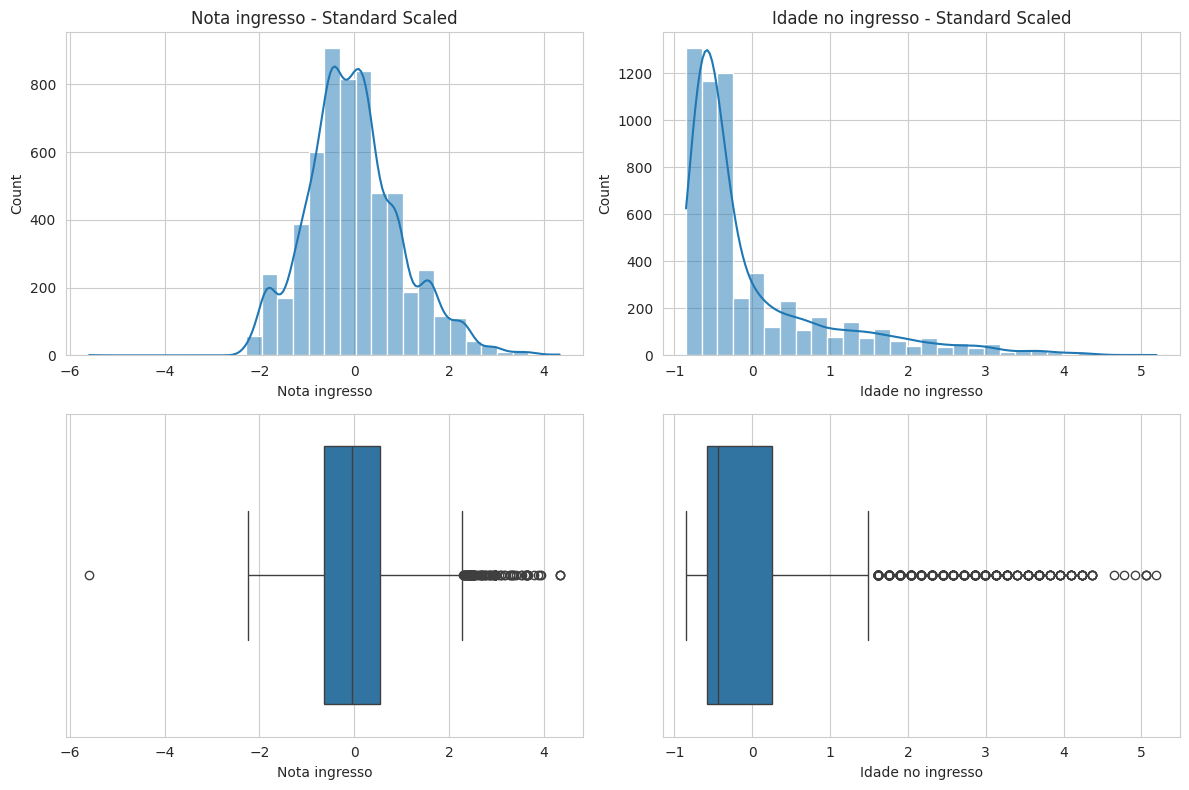

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(scaled_standard['Nota ingresso'], bins=30, kde=True, ax=axes[0, 0])
axes[0, 0].set_title("Nota ingresso - Standard Scaled")

sns.histplot(scaled_standard['Idade no ingresso'], bins=30, kde=True, ax=axes[0, 1])
axes[0, 1].set_title("Idade no ingresso - Standard Scaled")

sns.boxplot(x=scaled_standard['Nota ingresso'], ax=axes[1, 0])

sns.boxplot(x=scaled_standard['Idade no ingresso'], ax=axes[1, 1])

plt.tight_layout()
plt.show()

In [ ]:
scaled_standard[['Nota ingresso', 'Idade no ingresso']].describe()

,Nota ingresso,Idade no ingresso
count,5.742000e+03,5.742000e+03
mean,6.409981e-16,-4.652805e-16
std,1.000087e+00,1.000087e+00
min,-5.590176e+00,-8.508391e-01
25%,-6.349542e-01,-5.761164e-01
50%,-5.239006e-02,-4.387550e-01
75%,5.375418e-01,2.480518e-01
max,4.333975e+00,5.193061e+00


Robust Scaler

In [ ]:
from sklearn.preprocessing import RobustScaler

#df para dados transformados
scaled_robust = df_imputed.copy()
#instaciar scaler
robust_scaler = RobustScaler()
#aplicar transformação
scaled_robust[['Nota ingresso', 'Idade no ingresso']] = robust_scaler.fit_transform(df_imputed[['Nota ingresso', 'Idade no ingresso']])

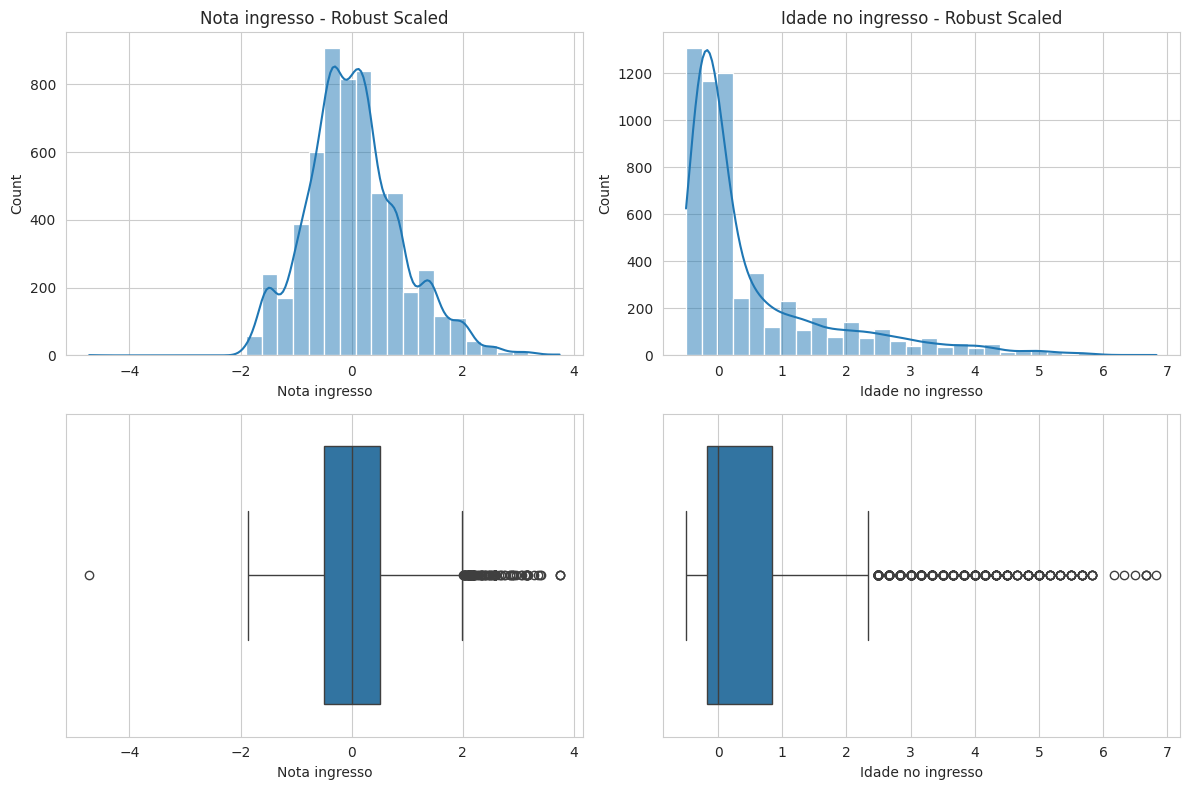

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(scaled_robust['Nota ingresso'], bins=30, kde=True, ax=axes[0, 0])
axes[0, 0].set_title("Nota ingresso - Robust Scaled")

sns.histplot(scaled_robust['Idade no ingresso'], bins=30, kde=True, ax=axes[0, 1])
axes[0, 1].set_title("Idade no ingresso - Robust Scaled")

sns.boxplot(x=scaled_robust['Nota ingresso'], ax=axes[1, 0])

sns.boxplot(x=scaled_robust['Idade no ingresso'], ax=axes[1, 1])

plt.tight_layout()
plt.show()

In [ ]:
def describe_extended(df):
    desc = df.describe().T # count, mean, std, min, 25%, 50%, 75%, max

    return desc

def comparar(atributo):
  stats_original = describe_extended(df_imputed[[atributo]])
  stats_standard = describe_extended(scaled_standard[[atributo]])
  stats_robust = describe_extended(scaled_robust[[atributo]])

  # Construir tabela juntando tudo
  tabela = pd.concat(
    {
        "Original": stats_original,
        "StandardScaler": stats_standard,
         "RobustScaler": stats_robust,
    },
    axis=0
  )
  return tabela.T

In [ ]:
comparar("Nota ingresso")

,Original,StandardScaler,RobustScaler
,Nota ingresso,Nota ingresso,Nota ingresso
count,5742.000000,5.742000e+03,5742.000000
mean,126.764406,6.409981e-16,0.044683
std,14.591939,1.000087e+00,0.852956
min,45.200000,-5.590176e+00,-4.723075
25%,117.500000,-6.349542e-01,-0.496858
50%,126.000000,-5.239006e-02,0.000000
75%,134.607500,5.375418e-01,0.503142
max,190.000000,4.333975e+00,3.741049


In [ ]:
comparar("Idade no ingresso")


,Original,StandardScaler,RobustScaler
,Idade no ingresso,Idade no ingresso,Idade no ingresso
count,5742.000000,5.742000e+03,5742.000000
mean,23.194166,-4.652805e-16,0.532361
std,7.280701,1.000087e+00,1.213450
min,17.000000,-8.508391e-01,-0.500000
25%,19.000000,-5.761164e-01,-0.166667
50%,20.000000,-4.387550e-01,0.000000
75%,25.000000,2.480518e-01,0.833333
max,61.000000,5.193061e+00,6.833333


Tanto para a Nota de Ingresso como a Idade no Ingresso, o método **Standard Scaler** é o que indica a média mais próxima de 0 e o desvio padrão mais próximo de 1, logo este será o método aplicado.

In [ ]:
scaled_standard.describe()

,Ordem de ingresso,Nota ingresso,Bolseiro,Idade no ingresso,Deslocado,Categoria
count,5742.000000,5.742000e+03,5742.000000,5.742000e+03,5742.000000,5742.000000
mean,1.730059,6.409981e-16,0.228144,-4.652805e-16,0.521247,0.568443
std,1.314212,1.000087e+00,0.419672,1.000087e+00,0.499592,0.495337
min,0.000000,-5.590176e+00,0.000000,-8.508391e-01,0.000000,0.000000
25%,1.000000,-6.349542e-01,0.000000,-5.761164e-01,0.000000,0.000000
50%,1.000000,-5.239006e-02,0.000000,-4.387550e-01,1.000000,1.000000
75%,2.000000,5.375418e-01,0.000000,2.480518e-01,1.000000,1.000000
max,9.000000,4.333975e+00,1.000000,5.193061e+00,1.000000,1.000000


### Tratamento de dados desbalanceados

In [ ]:
# Distribuição da variável Categoria
# nota: 1- não diplomado
freq = scaled_standard["Categoria"].value_counts()
freq_pct = scaled_standard["Categoria"].value_counts(normalize=True) * 100

print("Frequências absolutas:")
print(freq)
print("\nFrequências relativas (%):")
print(freq_pct.round(2))

Frequências absolutas:
Categoria
1.0    3264
0.0    2478
Name: count, dtype: int64

Frequências relativas (%):
Categoria
1.0    56.84
0.0    43.16
Name: proportion, dtype: float64


Oversampling

In [ ]:
classe_maj = scaled_standard["Categoria"].value_counts().idxmax()
classe_maj

np.float64(1.0)

In [ ]:
classe_min = scaled_standard["Categoria"].value_counts().idxmin()
classe_min

np.float64(0.0)

Pode afirmar-se que a categoria **Não Diplomado** é a **maioritária**.


In [ ]:
n_min = scaled_standard["Categoria"].value_counts().min()

# Separar as duas classes
df_min = scaled_standard[scaled_standard["Categoria"] == classe_min]
df_maj = scaled_standard[scaled_standard["Categoria"] == classe_maj]
train_over = df_min.copy()
# número de exemplos a acrescentar para igualar a classe maior
n_to_add = len(df_maj) - len(df_min)

df_min_extra = df_min.sample(n=n_to_add, replace=True, random_state=42)

df_over = pd.concat([train_over, df_min_extra, df_maj], axis=0)

In [ ]:
print("\nDistribuição após oversampling:")
print(df_over["Categoria"].value_counts())
print("\nDistribuição após oversampling (%):")
print((df_over["Categoria"].value_counts(normalize=True) * 100).round(2))


Distribuição após oversampling:
Categoria
0.0    3264
1.0    3264
Name: count, dtype: int64

Distribuição após oversampling (%):
Categoria
0.0    50.0
1.0    50.0
Name: proportion, dtype: float64


In [ ]:
df_over.describe()

,Ordem de ingresso,Nota ingresso,Bolseiro,Idade no ingresso,Deslocado,Categoria
count,6528.000000,6528.000000,6528.000000,6528.000000,6528.000000,6528.000000
mean,1.745864,0.011045,0.247549,-0.027048,0.525582,0.500000
std,1.325949,0.992898,0.431621,0.986587,0.499383,0.500038
min,0.000000,-5.590176,0.000000,-0.850839,0.000000,0.000000
25%,1.000000,-0.614393,0.000000,-0.576116,0.000000,0.000000
50%,1.000000,-0.045536,0.000000,-0.438755,1.000000,0.500000
75%,2.000000,0.543881,0.000000,0.110690,1.000000,1.000000
max,9.000000,4.333975,1.000000,5.193061,1.000000,1.000000


Para o balanceamento da variável alvo **Categoria**, optou-se pela técnica de **Oversampling** (sobre-amostragem da classe minoritária) em detrimento do Undersampling, pois o dataset possui uma dimensão moderada (~5700 registos). A aplicação de Undersampling implicaria a **eliminação física de centenas de registos da classe maioritária** (Não Diplomado). Dado que o objetivo do projeto é identificar padrões complexos de sucesso/insucesso, descartar dados reais resultaria numa perda significativa de informação, empobrecendo o treino do modelo.

O desequilíbrio entre classes não é extremo (aprox. 57% vs 43%). O Oversampling permite corrigir esta ligeira discrepância aumentando a representatividade da classe Diplomado sem introduzir o risco de enviesamento massivo que ocorreria se o desequilíbrio fosse maior entre as classes.

In [ ]:
#gravar dados
df_over.to_csv("dataset_PIAES_processado_ana_estreia.csv", sep=',', index=False)